# Personal Finance Expenses Exploratory Data Analysis

**Author:** Holly Praiswater

This notebook explores a personal finance expense dataset containing individual financial transactions. The goal is to examine the structure and quality of the data and identify patterns in transaction amounts and spending categories.

In [1]:
import pandas as pd

## 1. Load the Data

The personal finance expense data is stored in `Expenses_clean.csv`.
The dataset will be loaded into a pandas DataFrame for exploration.

In [2]:
df = pd.read_csv("../data/raw/Expenses_clean.csv")

## 2. Inspect the Data

Next, I will examine the size and structure of the dataset, including the number of row and columns and the data types of each variable.

In [3]:
print("Shape:", df.shape)

df.info()

Shape: (938, 6)
<class 'pandas.DataFrame'>
RangeIndex: 938 entries, 0 to 937
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   date_time  938 non-null    str    
 1   category   938 non-null    str    
 2   account    938 non-null    str    
 3   amount     938 non-null    float64
 4   currency   938 non-null    str    
 5   tags       938 non-null    str    
dtypes: float64(1), str(5)
memory usage: 44.1 KB


### Obeservation

The dataset contains 938 rows and 6 columns. The columns include `date_time`, `category`, `account`, `amount`, `currency `, and `tags`.

The `amount` column is numeric, while the remaining columns are stored as text. All 938 rows contain a value in each column.

## 3. Check Missing Values and Data Quality

Next, I will check the dataset for missing values and duplicate rows to identify possible data quality issues.

In [4]:
print("Missing values by column:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values by column:
date_time    0
category     0
account      0
amount       0
currency     0
tags         0
dtype: int64

Duplicate rows:
145


### Observation

No missing values were found in any of the six columns. However, 145 duplicate rows were identified.

The duplicate rows were not automatically removed because repeated transactions could represent legitimate separate expenses rather than data errors. Further investigation would be needed before deciding whether to remove them.

## 4. Descriptive Statistics

Next, I will examine descriptive statistics for the numeric variables to better understand the distribution of transaction amounts.

In [5]:
df.describe()

,amount
count,938.000000
mean,15.842217
std,78.291145
min,0.000000
25%,1.000000
50%,2.000000
75%,10.000000
max,1172.000000


### Observation

Transaction amounts vary considerably. The median transaction amount is 2, and 75% of transactions have an amount of 10 or less. However, the mean is 15.84 and the maximum transaction amount is 1,172.

The large difference between the median and mean suggests that a small number of much larger transactions are pulling the average upward. These unusually large transactions may be worth investigating further.

## 5. Visualize Transaction Amounts

A histogram can help show how transaction amounts are distributed and whether most transactions are similar in size or vary considerably.

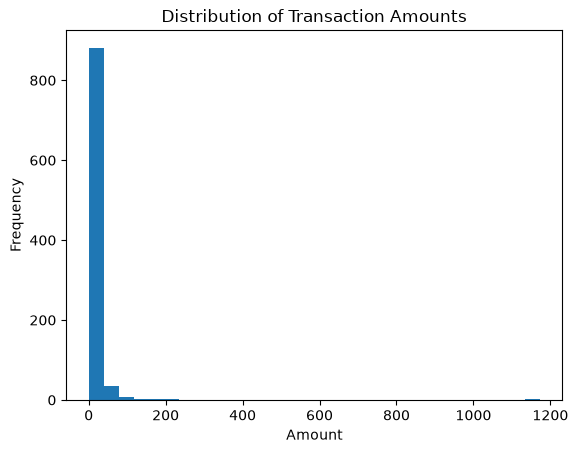

In [6]:
import matplotlib.pyplot as plt

df["amount"].plot(kind="hist", bins=30)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Amount")
plt.ylabel("Frequency")
plt.show()

### Observation

The transaction amounts are strongly right-skewed. Most transactions are clustered at the lower end of the distribution, while a small number of much larger transactions extend far to the right.

This supports the descriptive statistics, where the median transaction was only 2 but the mean was 15.84. The unusually large transactions increase the mean even though most transactions are relatively small.

## 6. Explore Expense Categories

Next, I will exmaine how frequently each expense category appears in the dataset. This can help identify which types of transactions occur most often.

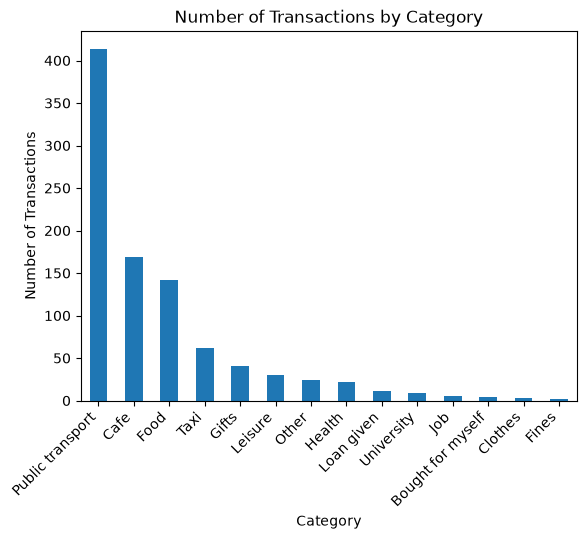

In [7]:
category_counts = df["category"].value_counts()

category_counts.plot(kind="bar")

plt.title("Number of Transactions by Category")
plt.xlabel("Category")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45, ha="right")
plt.show()

### Observation

Public transport is the most frequent expense category by a large margin, followed by Cafe and Food. Several other categories occur much less frequently.

However, the number of transactions does not necessarily indicate where the most money was spent. A category could contain many small transactions while another category could contain fewer but much larger transactions.

## 7. Compare Total Spending by Category

Although transaction frequency shows which categories occur most often, it does not show which categories account for the greatest total spending. Next, I will calculate the total transaction amount for each category.

In [8]:
spending_by_category = (
    df.groupby("category")["amount"].sum().sort_values(ascending=False)
)

spending_by_category

category
Loan given           2809.0
Other                2699.0
Food                 1538.0
Cafe                 1424.0
Gifts                1277.0
Bought for myself    1273.0
Leisure               945.0
Health                804.0
Taxi                  770.0
Clothes               548.0
Public transport      514.0
Job                   133.0
University             81.0
Fines                  45.0
Name: amount, dtype: float64

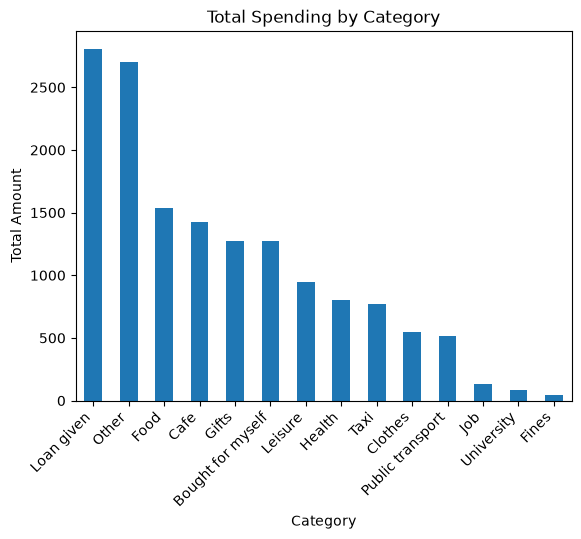

In [9]:
spending_by_category.plot(kind="bar")

plt.title("Total Spending by Category")
plt.xlabel("Category")
plt.ylabel("Total Amount")
plt.xticks(rotation=45, ha="right")
plt.show()

### Observation

Loan given had the highest total spending at 2,809, followed by Other at 2,699. This differs form the transaction frequency results, where Public transport was by far the most common category/

Public transport had many transactions but only 514 in total spending. This shows that the category with the most transactions is not necessarily the category where the most money is spent. Looking at both transaction frequency and toatl amount provide a more complete picture of spending patterns.

## 8. Investigate Large Transactions

The transaction amount distribution showed a small number of unusually large values. I will examine the largest transaction to better understand what is causing the right-skewed distribution.

In [10]:
df.nlargest(10, "amount")

,date_time,category,account,amount,currency,tags
808,2025-03-05 00:00:00,Loan given,acct_1,1172.0,BYN,tag_1
809,2025-03-05 00:00:00,Other,acct_1,1156.0,BYN,tag_1
207,2025-09-29 00:00:00,Bought for myself,acct_1,1129.0,BYN,tag_1
140,2025-10-15 00:00:00,Loan given,acct_1,854.0,BYN,tag_1
638,2025-04-29 00:00:00,Other,acct_1,654.0,BYN,tag_1
267,2025-09-11 00:00:00,Loan given,acct_1,457.0,BYN,tag_1
228,2025-09-25 00:00:00,Food,acct_1,313.0,BYN,tag_1
65,2025-11-05 00:00:00,Clothes,acct_1,299.0,BYN,tag_1
225,2025-09-26 00:00:00,Leisure,acct_1,232.0,BYN,tag_1
901,2025-01-23 00:00:00,Other,acct_1,210.0,BYN,tag_1


### Observation

The largest transaction was 1,172 in the Loan given category. The next two largest transactions were 1,156 in Other and 1.129 in Bought for Myself.

These few large transactions help explain the strongly right-skewed distribution and why the mean is much higher than the median. The large transactions should not automatically be considered errors because they may represent legitimate expenses, but they would be useful to investigate further.

## 9. Conclusions and Next Steps

This exploratory data analysis examined 938 personal expense transactions across 14 spending categories. No missing values were found, although 145 duplicate rows were identified and would need further investigation before being remvoed.

Most transactions were relatively small, but a few large transactions caused the amount distribution to be strongly right-skewed. Public transport was the most frequent expense category, while Loan given had the highest toatl spending. This demonstrated that transaction frequency and total spending can show different patterns within the dataset.

If I continued this analysis, I would investigate spending patterns over time, examine the duplicate transactions more closely, and exploe the unusually large transactions to determine how they affect overall spending patterns.

## Dataset Source

This project uses the **Financial Transactions Dataset (Expenses & Income)** from Kaggle. The `Expenses_clean.csv` file contains individual expense transactions with information about the transaction date, category, account, amount, currency, and tags.

Source: Kaggle — Financial Transactions Dataset (Expenses & Income)  
https://www.kaggle.com/datasets/artemkabseu/financial-transactions-dataset-expenses-and-income